In [9]:
import torch
import torchvision.models as models
import torchvision.transforms as transforms
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import torch.nn.functional as F



In [10]:
# Cargar el modelo VGG16 preentrenado
model = models.vgg16(weights=models.VGG16_Weights.DEFAULT)
model.eval()



VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

In [11]:
# Preprocesamiento de la imagen (perro o gato)
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], 
                         std=[0.229, 0.224, 0.225])
])



In [12]:
# Reemplaza con la ruta de una imagen de tu dataset de perros o gatos
#img_path = '0006.png' 
img_path = 'cat.jpeg' 
image = Image.open(img_path).convert('RGB')
input_tensor = transform(image).unsqueeze(0) # Añadir dimensión de lote (batch)

# Seleccionar las capas representativas en VGG16
# VGG16 organiza sus capas convolucionales en 'features'. 
# Usaremos la primera capa de los bloques 1, 3 y 5.
layers_to_extract = {
    'Bajo Nivel (Bloque 1)': 0,   # Primeras capas: bordes y colores
    'Medio Nivel (Bloque 3)': 10,  # Capas intermedias: patrones y texturas
    'Alto Nivel (Bloque 5)': 24   # Capas profundas: partes del animal
}

activation = {}
def get_activation(name):
    def hook(model, input, output):
        activation[name] = output.detach()
    return hook

# Registrar los ganchos (hooks) en las capas seleccionadas
hooks = []
for name, idx in layers_to_extract.items():
    h = model.features[idx].register_forward_hook(get_activation(name))
    hooks.append(h)

# Propagación hacia adelante (Forward pass)
with torch.no_grad():
    _ = model(input_tensor)

# Remover los ganchos al finalizar
for h in hooks:
    h.remove()



In [13]:
# Función para graficar los mapas de características
def plot_feature_maps(activations_dict, num_filters=16):
    for layer_name, act in activations_dict.items():
        # act tiene forma [1, Canales, Alto, Ancho]
        feature_maps = act[0].cpu().numpy()
        total_channels = feature_maps.shape[0]
        num_to_show = min(num_filters, total_channels)
        
        fig, axes = plt.subplots(4, 4, figsize=(8, 8))
        fig.suptitle(f'Feature Maps - {layer_name}', fontsize=14, fontweight='bold')
        
        for j in range(num_to_show):
            row = j // 4
            col = j % 4
            ax = axes[row, col]
            # Muestra el mapa de características de un canal específico
            ax.imshow(feature_maps[j], cmap='viridis')
            ax.axis('off')
            
        plt.tight_layout()
        plt.show()



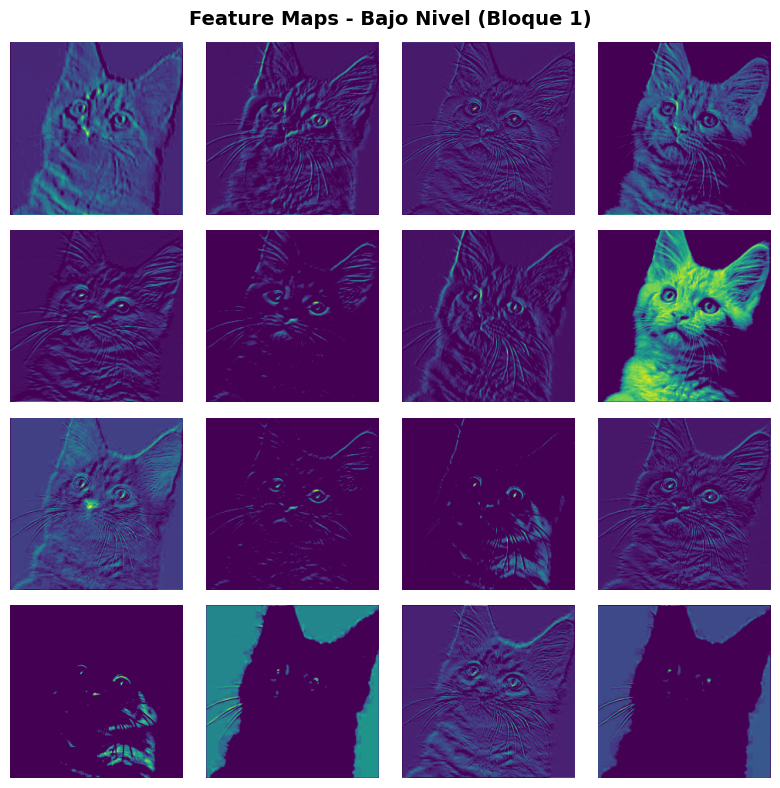

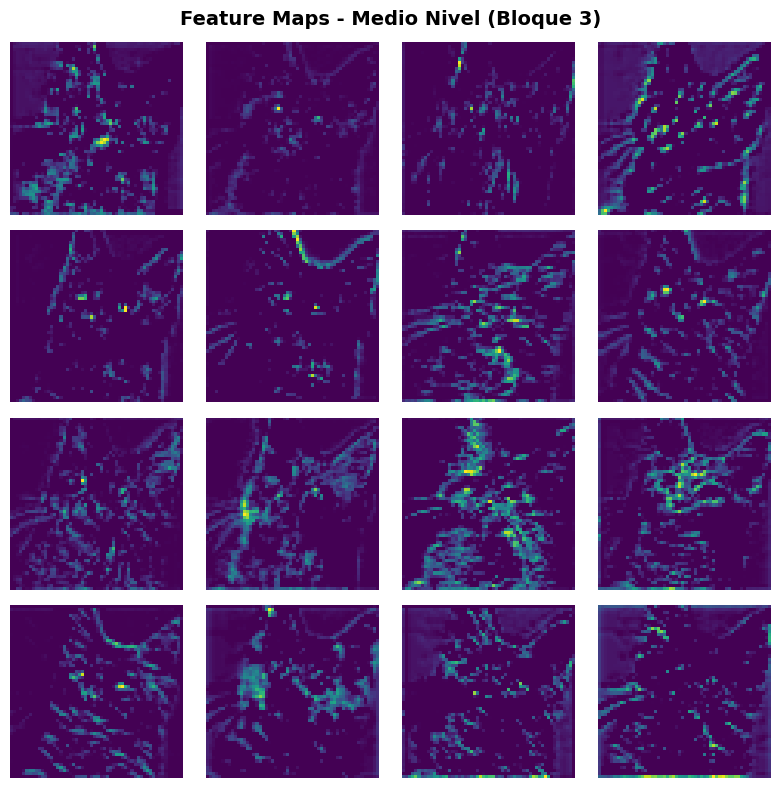

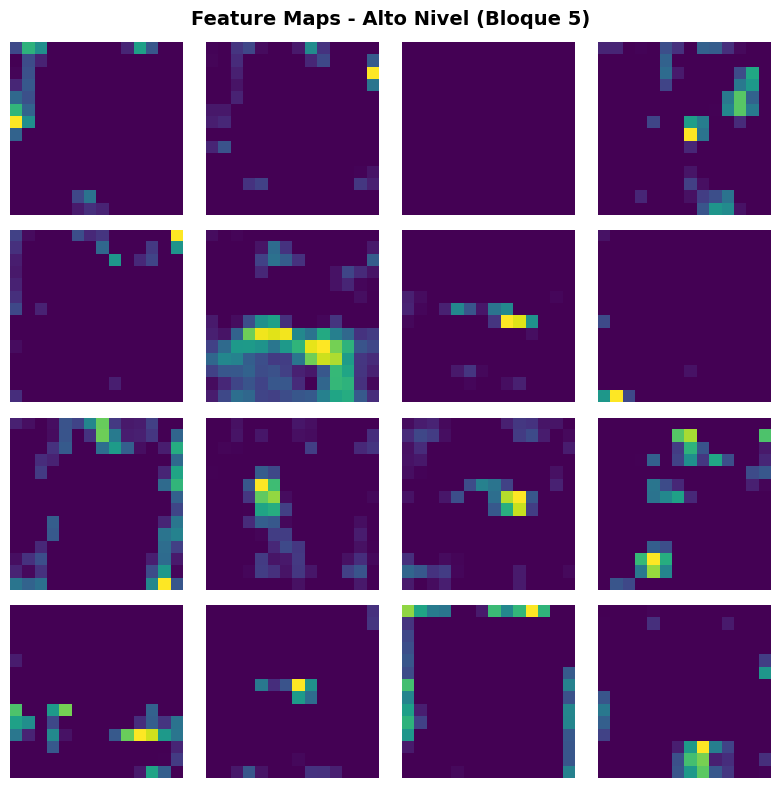

In [14]:
# Ejecutar la visualización
plot_feature_maps(activation)

In [15]:
def plot_only_heatmaps(activations_dict, num_filters=16):
    for layer_name, act in activations_dict.items():
        feature_maps = act[0].cpu().numpy()
        total_channels = feature_maps.shape[0]
        num_to_show = min(num_filters, total_channels)
        
        fig, axes = plt.subplots(4, 4, figsize=(8, 8))
        # Título más preciso para la maestría
        fig.suptitle(f'Activaciones Puras (Interpoladas) - {layer_name}', fontsize=14, fontweight='bold')
        
        for j in range(num_to_show):
            row = j // 4
            col = j % 4
            ax = axes[row, col]
            
            # Interpolación bilineal para suavizar el mapa de baja resolución
            # Se hace directamente sobre el tensor de activación
            map_resized = F.interpolate(act[:, j:j+1, :, :], size=(224, 224), mode='bilinear', align_corners=False)
            
            # Graficar SOLO el mapa de calor interpolado (sin superposición)
            # Usamos cmap='jet' para que coincida con la convención de colores
            ax.imshow(map_resized[0, 0].cpu().numpy(), cmap='jet')
            ax.axis('off')
            
        plt.tight_layout()
        plt.show()



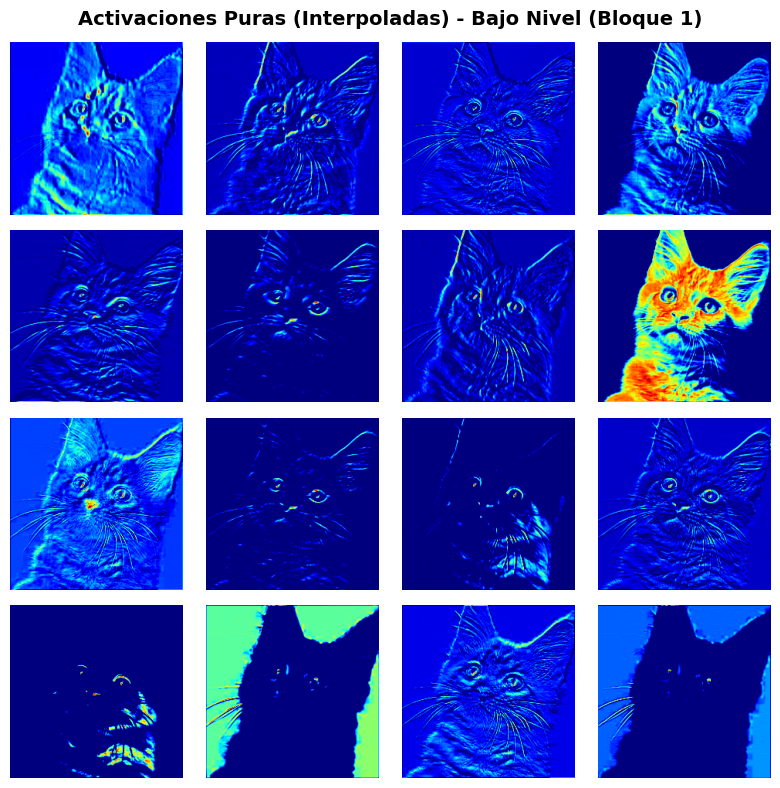

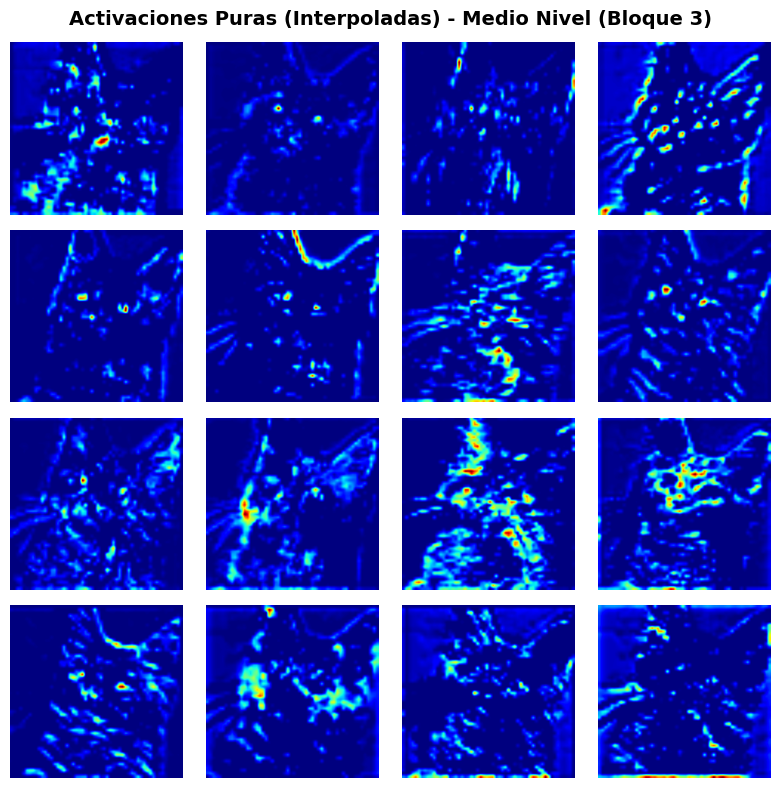

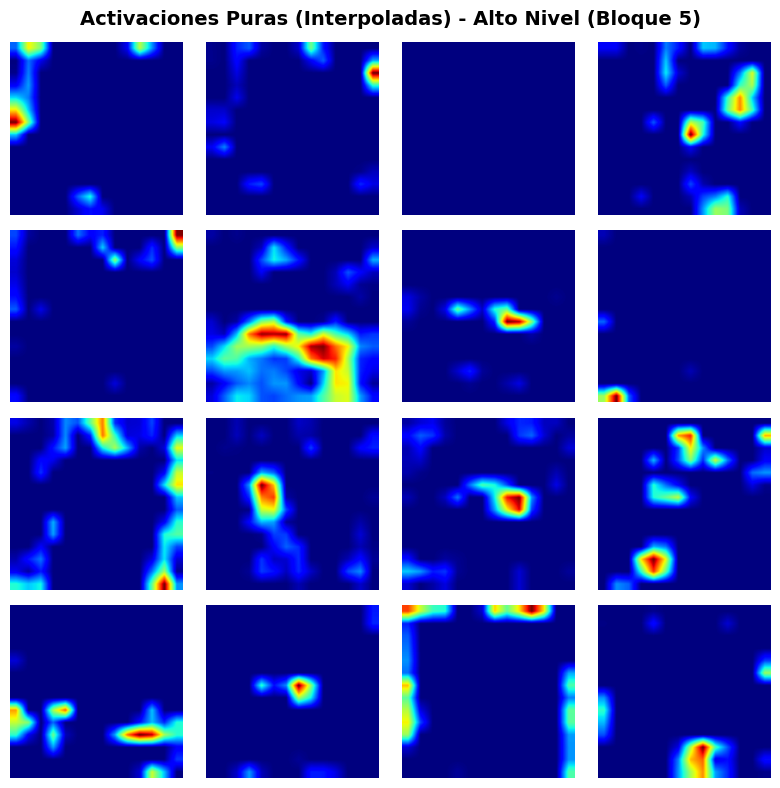

In [16]:
# Ejecutar la visualización corregida
plot_only_heatmaps(activation)